## 3.1 Volume et dynamique des écoutes

On regarde comment le total des streams du Top 200 évolue dans chaque pays : la tendance (3.1.1), la saisonnalité (3.1.2) et les semaines exceptionnelles (3.1.3).

In [1]:
## Préparation : on importe les outils et on indique où se trouve la base

import pandas as pd  
import matplotlib.pyplot as plt  

CHEMIN_BASE="C:/Users/nomutilisateur/Documents/base_complete.csv"  


In [2]:
base=pd.read_csv(CHEMIN_BASE)  # On charge la base des classements dans un tableau (une ligne par chanson, par pays et par semaine)

base["semaine"]= pd.to_datetime(base["semaine"])   #La semaine est lue comme du texte : on la convertit en vraie date, pour pouvoir trier, calculer le jour de la semaine et regrouper par mois

base = base[base["semaine"] >= "2022-10-06"]    ## Cinq pays ont été téléchargés depuis janvier 2022 et cinq depuis octobre 2022. Pour comparer les pays sur la même période, on garde les semaines à partir du 6 octobre 2022


In [3]:
print(base.shape,base["pays"].nunique(),base["semaine"].nunique(),base.columns.tolist())  # vérification : nombre de lignes et de colonnes, nombre de pays, nombre de semaines, noms des colonnes


(419891, 11) 10 210 ['rank', 'uri', 'artist_names', 'track_name', 'source', 'peak_rank', 'previous_rank', 'weeks_on_chart', 'streams', 'pays', 'semaine']


### 3.1.1 Évolution du total des streams du Top 200

In [4]:
# étape 1 : pour chaque pays et chaque semaine, on additionne les streams des 200 chansons du classement
totaux=base.groupby(["pays","semaine"])["streams"].sum().reset_index()

In [5]:
print(totaux.shape, totaux["streams"].min())  # vérification : 2100 lignes (10 pays x 210 semaines) et le plus petit total

(2100, 3) 5135953


In [6]:
pays_liste = totaux["pays"].unique()  # la liste des 10 pays, pour faire un graphique par pays

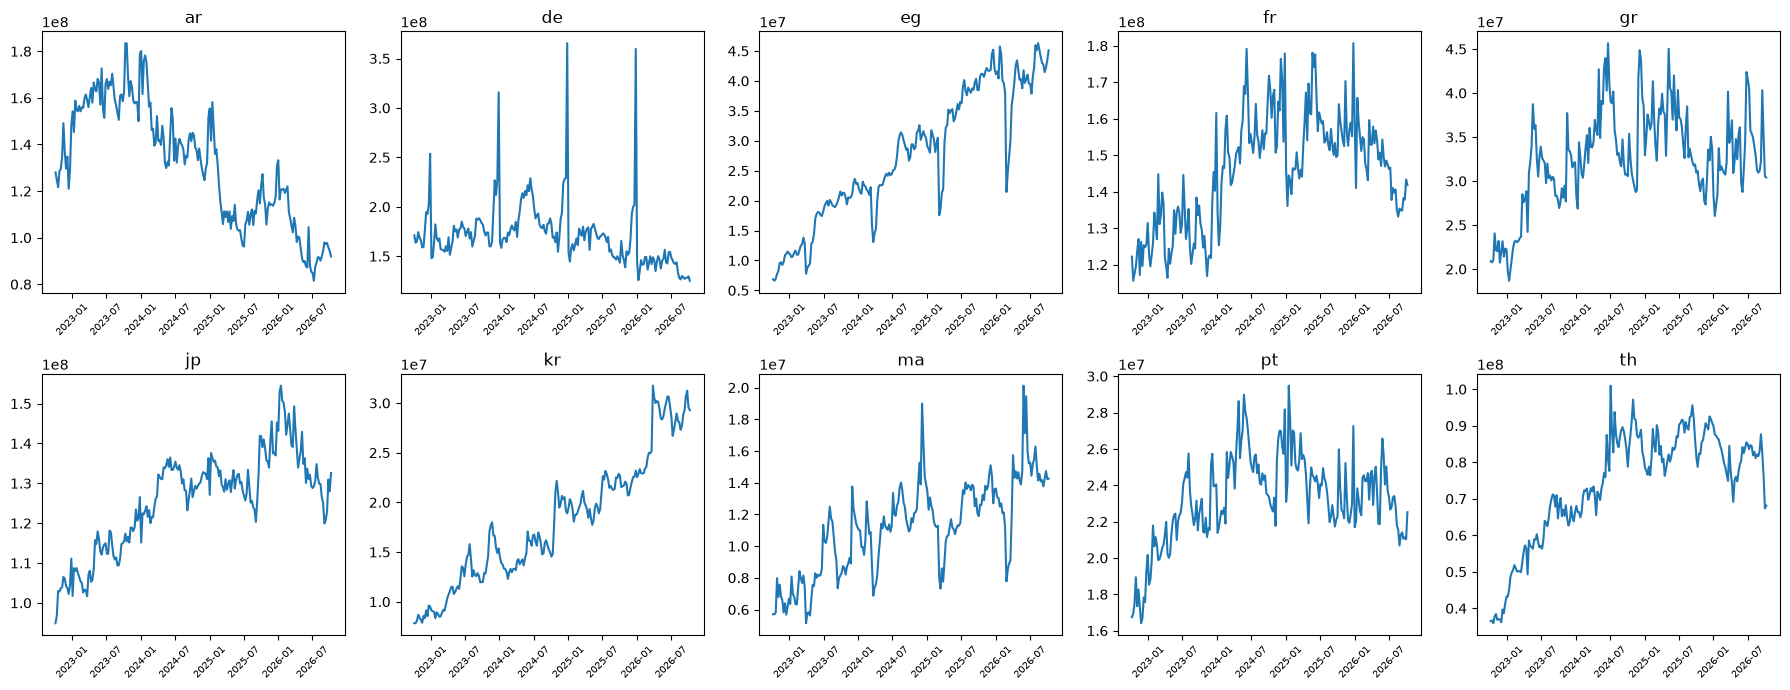

In [7]:
plt.figure(figsize=(18, 7))  # une grande figure pour placer les 10 graphiques
for i in range(10):  # on répète pour chacun des 10 pays
    p = pays_liste[i]  # le pays numéro i
    un_pays = totaux[totaux["pays"] == p]  # on garde seulement les lignes de ce pays
    plt.subplot(2, 5, i + 1)  # 2 lignes et 5 colonnes de graphiques : on dessine dans la case i + 1
    plt.plot(un_pays["semaine"], un_pays["streams"])  # la courbe : les semaines en abscisse, le total des streams en ordonnée
    plt.title(p)  # le nom du pays en titre
    plt.xticks(rotation=45, fontsize=7) ## je penche les dates à 45° et je les écris en petit pour qu'elles ne se chevauchent pas
plt.tight_layout() # j'arrange les 10 graphiques pour que les titres et les dates ne se touchent pas
plt.show()  # on affiche la figure

**Ce que montrent les courbes**

- **Égypte, Corée du Sud** : hausse continue sur toute la période, par paliers. En Égypte, il y a aussi des chutes courtes chaque printemps (mars-avril).
- **Thaïlande, Japon** : hausse jusqu'en 2024 (fin de la hausse début 2024 au Japon, mi-2024 en Thaïlande), puis le total reste à peu près stable ou baisse légèrement.
- **Maroc** : hausse en 2023, puis le total devient très irrégulier, avec de gros pics fin 2024 et début 2026.
- **France, Portugal, Grèce** : hausse jusqu'à un niveau haut en 2024, puis baisse : dès 2024 au Portugal, à partir de mi-2025 en France. En Grèce, le total varie beaucoup en 2025-2026, avec une légère baisse.
- **Argentine** : niveau haut pendant tout 2023, puis baisse continue depuis début 2024, avec une chute nette début 2025.
- **Allemagne** : niveau assez plat (petite bosse mi-2024), qui baisse en 2025-2026, avec un pic très haut chaque fin décembre (probablement les chansons de Noël, à vérifier en 3.1.3).

In [8]:
debut = totaux.groupby("pays").head(4).groupby("pays")["streams"].mean()  # pour chaque pays, moyenne des 4 premières semaines (octobre 2022)
fin = totaux.groupby("pays").tail(4).groupby("pays")["streams"].mean()  # pour chaque pays, moyenne des 4 dernières semaines (octobre 2026)

variation = (fin - debut) / debut * 100  # évolution en % entre le début et la fin

resultat = pd.DataFrame({"debut": debut, "fin": fin, "variation_%": variation.round(1)})  # on réunit les trois résultats dans un tableau (variation arrondie à 1 chiffre après la virgule)
print(resultat)  # on affiche le tableau

             debut           fin  variation_%
pays                                         
ar    1.257255e+08  9.492123e+07        -24.5
de    1.685546e+08  1.277431e+08        -24.2
eg    7.036186e+06  4.307063e+07        512.1
fr    1.186938e+08  1.403080e+08         18.2
gr    2.168234e+07  3.408876e+07         57.2
jp    9.940037e+07  1.286121e+08         29.4
kr    8.118571e+06  3.017595e+07        271.7
ma    6.299530e+06  1.437164e+07        128.1
pt    1.752690e+07  2.143008e+07         22.3
th    3.673130e+07  7.358771e+07        100.3


**Ce que montre le tableau**

Le tableau compare la moyenne des 4 premières semaines (octobre 2022) à celle des 4 dernières (octobre 2026). Comme les deux périodes tombent en octobre, la saison ne fausse pas la comparaison.

- **8 pays sur 10 sont en hausse.** Les plus fortes : Égypte (+512 %), Corée (+272 %), Maroc (+128 %) et Thaïlande (+100 %). Plus faibles : Grèce (+57 %), Japon (+29 %), Portugal (+22 %), France (+18 %).
- **2 pays sont en baisse** : Argentine (−24,5 %) et Allemagne (−24,2 %).
- Le tableau précise ce que les courbes ne montrent pas bien : l'Allemagne est en baisse, ce que les pics de Noël cachaient. À l'inverse, la France, le Portugal et la Grèce restent au-dessus de leur niveau de 2022, malgré leur baisse récente.

**Limites**

- Chaque courbe a sa propre échelle : on compare les formes, pas les niveaux entre pays.
- On mesure le total du Top 200, pas toute l'écoute du pays. Une baisse peut venir d'une écoute plus dispersée, sur plus de chansons hors du Top 200.
- Le tableau compare seulement le début et la fin, pas ce qui se passe entre les deux. C'est pour ça qu'il faut le lire avec les courbes.
- On décrit les évolutions, on ne les explique pas encore.